
---
date: "2026-10-25"
date-modified: last-modified
format:
  html:
    toc: true
---


# Integer Programs and LP Relaxation

**Prerequisites:** [Linear Programs](linear-programs.ipynb) · [Formulating Problems as Linear Programs](lp-modeling.ipynb)

## 1\. Integer Programs

::: {#def-integer-program}
## Integer Program

An **integer program** (IP) is an LP together with the requirement $x \in \mathbb{Z}^n$:
$$
\text{maximize } c^{\mathsf T}x \quad \text{subject to } Ax \le b,\ x \in \mathbb{Z}^n .
$$
Its feasible set is $P \cap \mathbb{Z}^n$, the lattice points of the polyhedron $P = \{x : Ax \le b\}$. A variable with the constraints $0 \le x_i \le 1$ and $x_i \in \mathbb{Z}$ is a **0–1 variable**: these conditions say exactly $x_i \in \{0, 1\}$. If only some variables must be integers, one speaks of a mixed integer program.
:::

::: {#exm-rounding-fails}
## The LP Optimum Can Be Far From the IP Optimum

Maximize $x_1 + x_2$ subject to $x_1 - 9x_2 \le 2$, $4x_2 \le 3$, $x_1, x_2 \ge 0$.

- Without integrality, the optimum is the corner $\big(\tfrac{35}4, \tfrac34\big)$ with value $9.5$ (the corners of $P$ are $(0, 0)$, $(2, 0)$, $\big(\tfrac{35}4, \tfrac34\big)$, $\big(0, \tfrac34\big)$).
- With $x \in \mathbb{Z}^2$: the constraint $x_2 \le \frac34$ forces $x_2 = 0$, then $x_1 \le 2$. The feasible set is $\{(0,0), (1,0), (2,0)\}$ and the optimum is $(2, 0)$ with value $2$.

None of the four lattice points around $\big(\tfrac{35}4, \tfrac34\big)$, namely $(8,0), (9,0), (8,1), (9,1)$, is feasible, and the integer optimum is at distance about $6.8$. In $\mathbb{R}^n$ a point has $2^n$ such surrounding lattice points, so even inspecting the neighbourhood of the LP optimum is expensive.
:::

LP optimum: [8.75 0.75] value 9.5 | integer points of P: [(0, 0), (1, 0), (2, 0)] | IP optimum: (2, 0)


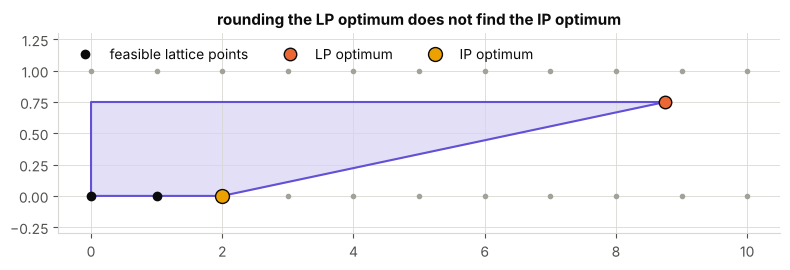

In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#d9d8d4", "#a3a29a"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})
from scipy.optimize import linprog

A = np.array([[1, -9], [0, 4]], float); b = np.array([2, 3], float)
res = linprog([-1, -1], A_ub=A, b_ub=b, bounds=[(0, None)] * 2)
lattice = [(i, j) for i in range(12) for j in range(3) if np.all(A @ np.array([i, j]) <= b + 1e-12)]
best = max(lattice, key=sum)
print("LP optimum:", res.x, "value", -res.fun, "| integer points of P:", lattice, "| IP optimum:", best)

corners = np.array([[0, 0], [2, 0], [35/4, 3/4], [0, 3/4]])
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.fill(*corners.T, color=VIOLET, alpha=0.18); ax.plot(*np.vstack([corners, corners[:1]]).T, color=VIOLET)
G = np.array([(i, j) for i in range(11) for j in range(2)])
ax.plot(*G.T, ".", color=FAINT, ms=6)
ax.plot(*np.array(lattice).T, "o", color=INK, ms=6, label="feasible lattice points")
ax.plot(*res.x, "o", color=ORANGE, ms=9, mec=INK, label="LP optimum")
ax.plot(*best, "o", color=YELLOW, ms=10, mec=INK, label="IP optimum")
ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.3, 1.3); ax.legend(loc="upper left", ncol=3)
ax.set_title("rounding the LP optimum does not find the IP optimum")
plt.tight_layout(); plt.show()


## 2\. Integer Programming Is Hard

::: {.callout-note}
## Informal: P and NP
A problem is in **P** if some algorithm solves every instance in a number of steps bounded by a polynomial in the size of the instance. It is in **NP** if a proposed solution can be *checked* in polynomial time. Every problem in P is in NP; whether P $=$ NP is a famous open question, and it is widely believed that P $\ne$ NP. A problem is **NP-hard** if a polynomial-time algorithm for it would give one for every problem in NP. These definitions are only sketched here; they are used to explain why some problems below are believed to have no efficient exact algorithm.
:::

::: {#def-cnf-sat}
## Satisfiability

Let $x_1, \dots, x_n$ be Boolean variables (values $0$ = false, $1$ = true). A **literal** is $x_i$ or its negation $\neg x_i$; a **clause** is a disjunction of literals, such as $x_1 \vee \neg x_3 \vee x_4$; a **formula in conjunctive normal form** (CNF) is a conjunction $C_1 \wedge \dots \wedge C_m$ of clauses. It is **satisfiable** if some assignment $x \in \{0,1\}^n$ makes every clause true. **SAT** is the problem of deciding satisfiability; it is NP-hard. We write $P_j$ and $N_j$ for the sets of indices of the variables appearing in $C_j$ without and with negation.
:::

::: {#prp-sat-to-ip}
## SAT as an Integer Program

A CNF formula $C_1 \wedge \dots \wedge C_m$ is satisfiable if and only if the following system has a solution:
$$
\sum_{i \in P_j} x_i + \sum_{i \in N_j} (1 - x_i) \ge 1 \quad (j = 1, \dots, m), \qquad 0 \le x_i \le 1,\quad x \in \mathbb{Z}^n .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-sat-to-ip
The last two conditions say $x \in \{0,1\}^n$, i.e. $x$ is an assignment. Under an assignment, the literal $x_i$ has truth value $x_i$ and the literal $\neg x_i$ has truth value $1 - x_i$, both in $\{0, 1\}$. The clause $C_j$ is true iff at least one of its literals has value $1$, iff the sum of the values of its literals is $\ge 1$. So $x$ solves the system iff it satisfies every clause. $\blacksquare$
:::

Hence an efficient algorithm for integer programs would decide SAT efficiently: integer programming is NP-hard. In contrast, LPs can be solved efficiently. The innocent-looking condition $x \in \mathbb{Z}^n$ changes the difficulty completely.

::: {#prp-max-sat-ip}
## MAX-SAT as an Integer Program

**MAX-SAT** asks for an assignment satisfying as many clauses of a CNF formula as possible. Its optimum equals the optimal value of
$$
\text{maximize } \sum_{j=1}^m t_j \quad \text{subject to } t_j \le \sum_{i \in P_j} x_i + \sum_{i \in N_j} (1 - x_i),\ \ 0 \le t_j \le 1,\ \ 0 \le x_i \le 1,\ \ x \in \mathbb{Z}^n,\ t \in \mathbb{Z}^m .
$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-max-sat-ip
Fix an assignment $x \in \{0,1\}^n$ and let $s_j(x) \in \{0, 1\}$ be the truth value of $C_j$. By the proof of @prp-sat-to-ip, the right-hand side of the $j$-th constraint is $\ge 1$ if $s_j(x) = 1$ and is $0$ if $s_j(x) = 0$. So the admissible $t_j \in \{0, 1\}$ are: $t_j \in \{0,1\}$ if $C_j$ is true, $t_j = 0$ if it is false. The largest value of $\sum t_j$ for this $x$ is therefore the number of true clauses. Maximizing also over $x$ gives the MAX-SAT optimum. $\blacksquare$
:::

## 3\. LP Relaxation

::: {#def-lp-relaxation}
## LP Relaxation

The **LP relaxation** of an integer program is the LP obtained by deleting the condition $x \in \mathbb{Z}^n$. For 0–1 variables this replaces $x_i \in \{0, 1\}$ by $0 \le x_i \le 1$.
:::

::: {#prp-relaxation-bound}
## The Relaxation Bounds the Integer Optimum

Every feasible solution of an IP is feasible for its relaxation. Hence, if both have optimal values $v_{\mathrm{IP}}$ and $v_{\mathrm{LP}}$, then $v_{\mathrm{IP}} \le v_{\mathrm{LP}}$ for a maximization and $v_{\mathrm{IP}} \ge v_{\mathrm{LP}}$ for a minimization. If an optimal solution of the relaxation is integral, it is an optimal solution of the IP.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-relaxation-bound
$P \cap \mathbb{Z}^n \subseteq P$, and a maximum over a subset is at most the maximum over the whole set (dually for minima). If an optimal $x^*$ of the relaxation lies in $\mathbb{Z}^n$, it is IP-feasible, and its value $v_{\mathrm{LP}} \ge c^{\mathsf T}x$ for every $x \in P \cap \mathbb{Z}^n$, so it is IP-optimal. $\blacksquare$
:::

The relaxation is used in three ways:

1. **Bounds.** It gives, in polynomial time, a bound on an optimum that may be very hard to compute. A solution found by other means can then be judged: if its value is close to $v_{\mathrm{LP}}$, it is close to optimal.
2. **Exactness.** For some problems the relaxation always has an integral optimal solution, so the IP is solved by an LP; see [maximum-weight bipartite matching](bipartite-matching-lp.ipynb).
3. **Rounding.** A fractional optimum can be turned into a good integral solution, as for [cutting stock](lp-modeling.ipynb#exm-cutting-stock), [vertex cover](vertex-cover-and-independent-set.ipynb) and [set cover](set-cover-and-max-sat.ipynb).

## 4\. Facility Location

::: {#exm-facility-location}
## Facility Location as an Integer Program

There are possible sites $i \in F$ for facilities, with opening costs $f_i \ge 0$, and clients $j \in D$ ($D \ne \emptyset$); serving client $j$ from site $i$ costs $d_{ij} \ge 0$. Once a nonempty set $S \subseteq F$ of sites is opened, each client is served from a cheapest open site, so the cost is
$$
\operatorname{cost}(S) = \sum_{i \in S} f_i + \sum_{j \in D} \min_{i \in S} d_{ij} .
$$
With 0–1 variables $y_i$ (site $i$ is open) and $x_{ij}$ (client $j$ is served from $i$), consider
$$
\text{minimize } \sum_{i} f_iy_i + \sum_{i,j} d_{ij}x_{ij} \quad \text{subject to } \sum_{i \in F} x_{ij} = 1\ (j \in D), \quad x_{ij} \le y_i\ (i \in F, j \in D), \quad x, y \in \{0, 1\}.
$$
Its optimal value is $\min_{S \ne \emptyset} \operatorname{cost}(S)$.
:::

::: {.callout-tip collapse="true"}
## Proof of the claim in @exm-facility-location
Let $(x, y)$ be feasible and $S = \{i : y_i = 1\}$. Each client $j$ has exactly one $i$ with $x_{ij} = 1$, and then $y_i \ge x_{ij} = 1$, so $i \in S$; in particular $S \ne \emptyset$, and $\sum_i d_{ij}x_{ij} = d_{ij} \ge \min_{i' \in S} d_{i'j}$. Summing, the objective is $\ge \operatorname{cost}(S)$. Conversely, for $S \ne \emptyset$ put $y_i = 1$ exactly for $i \in S$ and $x_{ij} = 1$ for one cheapest $i \in S$ for client $j$ (and $0$ otherwise): this is feasible with objective $\operatorname{cost}(S)$. Hence the two minima coincide. $\blacksquare$
:::

In [2]:

from itertools import combinations
from scipy.optimize import milp, LinearConstraint, Bounds

rng = np.random.default_rng(11)
sites, clients = rng.uniform(0, 10, (5, 2)), rng.uniform(0, 10, (14, 2))
fcost = np.array([12, 9, 15, 8, 11], float)
d = np.linalg.norm(sites[:, None, :] - clients[None, :, :], axis=2)   # d[i, j]
nF, nD = d.shape

def cost(S):
    return fcost[list(S)].sum() + d[list(S)].min(axis=0).sum()
brute = min((cost(S), S) for r in range(1, nF + 1) for S in combinations(range(nF), r))

# variables: y (nF), then x (nF*nD) in row-major order x[i, j]
nv = nF + nF * nD
cvec = np.r_[fcost, d.ravel()]
rows, lo, hi = [], [], []
for j in range(nD):                                   # sum_i x_ij = 1
    r = np.zeros(nv); r[nF + np.arange(nF) * nD + j] = 1; rows.append(r); lo.append(1); hi.append(1)
for i in range(nF):
    for j in range(nD):                               # x_ij - y_i <= 0
        r = np.zeros(nv); r[nF + i * nD + j] = 1; r[i] = -1; rows.append(r); lo.append(-np.inf); hi.append(0)
cons = LinearConstraint(np.array(rows), lo, hi)
ip = milp(cvec, constraints=cons, integrality=np.ones(nv), bounds=Bounds(0, 1))
lp = milp(cvec, constraints=cons, integrality=np.zeros(nv), bounds=Bounds(0, 1))
print("brute force over all S:", round(brute[0], 4), "open sites", brute[1])
print("integer program:       ", round(ip.fun, 4), "open sites", tuple(int(i) for i in np.flatnonzero(ip.x[:nF] > 0.5)))
print("LP relaxation (lower bound; equal here):", round(lp.fun, 4))

brute force over all S: 67.0562 open sites (0, 1)
integer program:        67.0562 open sites (0, 1)
LP relaxation (lower bound; equal here): 67.0562
